In [ ]:
!pip install ucimlrepo


DRY BEAN DATASET

First 5 rows:
    Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRatio  \
0  28395    610.291       208.178117       173.888747     1.197191   
1  28734    638.018       200.524796       182.734419     1.097356   
2  29380    624.110       212.826130       175.931143     1.209713   
3  30008    645.884       210.557999       182.516516     1.153638   
4  30140    620.134       201.847882       190.279279     1.060798   

   Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  Roundness  \
0      0.549812       28715     190.141097  0.763923  0.988856   0.958027   
1      0.411785       29172     191.272751  0.783968  0.984986   0.887034   
2      0.562727       29690     193.410904  0.778113  0.989559   0.947849   
3      0.498616       30724     195.467062  0.782681  0.976696   0.903936   
4      0.333680       30417     195.896503  0.773098  0.990893   0.984877   

   Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4  
0     0.913

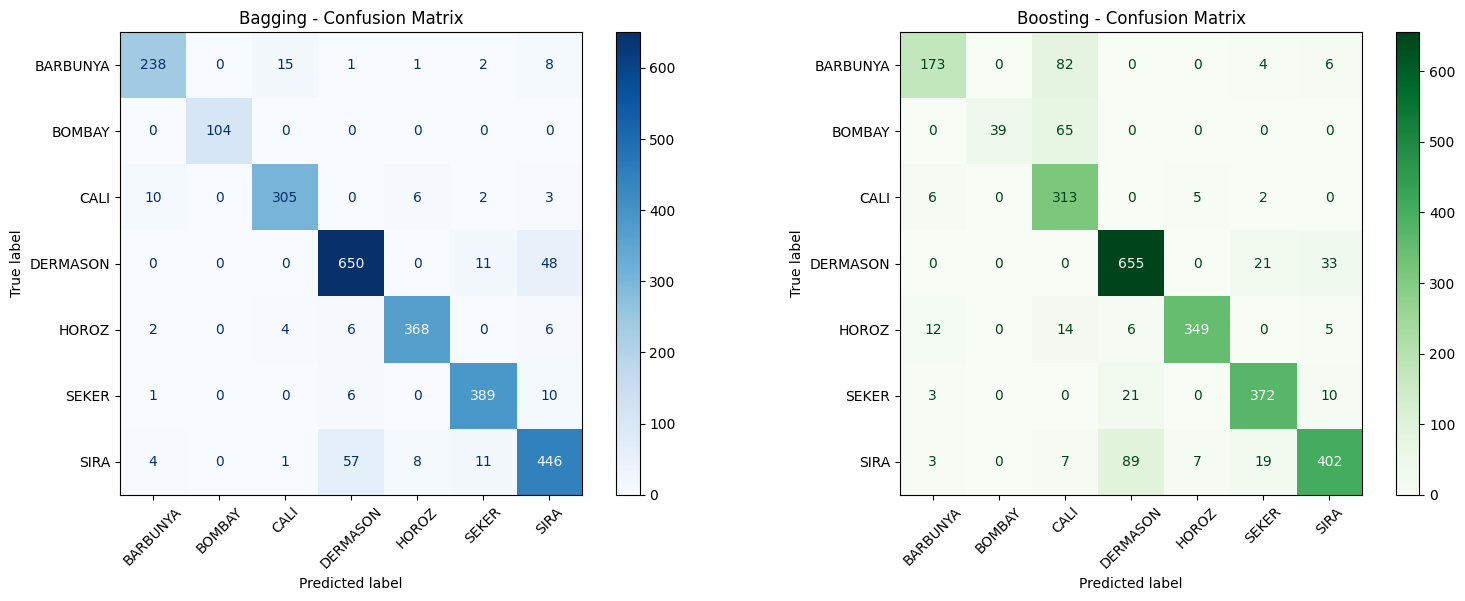

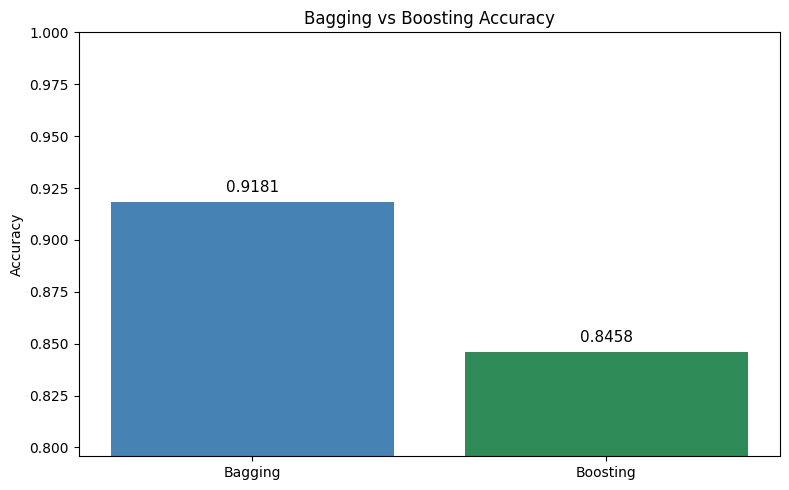

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


dry_bean = fetch_ucirepo(id=602)

X = dry_bean.data.features
y = dry_bean.data.targets.iloc[:, 0]


print("=" * 60)
print("DRY BEAN DATASET")
print("=" * 60)

print("\nFirst 5 rows:")
print(X.head())

print("\nDataset shape:")
print(X.shape)

print("\nFeature names:")
print(X.columns.tolist())

print("\nClass distribution:")
print(y.value_counts())


print("\nMissing values:")
print(X.isnull().sum().sum())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(X_train, y_train)

y_pred_bagging = bagging_model.predict(X_test)

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)


print("\n" + "=" * 60)
print("BAGGING CLASSIFIER")
print("=" * 60)

print(
    "\nAccuracy:",
    round(bagging_accuracy, 4)
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_bagging
    )
)

print("Confusion Matrix:")

print(
    confusion_matrix(
        y_test,
        y_pred_bagging
    )
)



boosting_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

boosting_model.fit(X_train, y_train)

y_pred_boosting = boosting_model.predict(X_test)

boosting_accuracy = accuracy_score(
    y_test,
    y_pred_boosting
)


print("\n" + "=" * 60)
print("BOOSTING CLASSIFIER")
print("=" * 60)

print(
    "\nAccuracy:",
    round(boosting_accuracy, 4)
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_boosting
    )
)

print("Confusion Matrix:")

print(
    confusion_matrix(
        y_test,
        y_pred_boosting
    )
)


print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

print(
    "\nBagging Accuracy :",
    round(bagging_accuracy, 4)
)

print(
    "Boosting Accuracy:",
    round(boosting_accuracy, 4)
)


class_names = sorted(y.unique())

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)


# Bagging confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_bagging,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45,
    ax=axes[0]
)

axes[0].set_title(
    "Bagging - Confusion Matrix"
)


# Boosting confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_boosting,
    display_labels=class_names,
    cmap="Greens",
    xticks_rotation=45,
    ax=axes[1]
)

axes[1].set_title(
    "Boosting - Confusion Matrix"
)

plt.tight_layout()
plt.show()



models = [
    "Bagging",
    "Boosting"
]

accuracies = [
    bagging_accuracy,
    boosting_accuracy
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    models,
    accuracies,
    color=[
        "steelblue",
        "seagreen"
    ]
)

plt.title(
    "Bagging vs Boosting Accuracy"
)

plt.ylabel("Accuracy")

plt.ylim(
    min(accuracies) - 0.05,
    1.0
)


# Display accuracy above bars
for bar, accuracy in zip(
    bars,
    accuracies
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{accuracy:.4f}",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()


In [ ]:
Yes. **It is absolutely possible to build a profitable algorithm for the Indian market.** But if by “profitable” you mean _“I can code an RSI/EMA/ML strategy, backtest it, and then reliably make 3–5% every month live”_, my honest answer is **probably not**.

 I searched recent Indian-market research, SEBI data, GitHub projects, Reddit experiences, and broader quantitative research on backtesting. The picture is actually quite interesting.

 ## My honest conclusion

 There are three very different statements:

 1. **“Can an algorithm make money in Indian markets?”** → **Yes.**
2. **“Can a retail developer realistically discover a persistent edge?”** → **Yes, but it is difficult and uncommon.**
3. **“Can I find one by trying indicators/ML models until the backtest looks good?”** → **Usually no.**

 The strongest evidence isn't that algorithms don't work. In fact, the latest SEBI data points in the opposite direction: large professional participants using algorithmic trading were responsible for essentially all of their reported profits in the equity-derivatives segment in FY26. Reuters reports that SEBI's August 2026 study found 87.7% of individual derivatives traders lost money, while proprietary traders and FPIs remained profitable, with **99% of their profits attributed to algorithmic trading entities**.  Reuters+1

 But—and this is a _huge_ but—that doesn't mean a retail trader can simply copy professional algo trading.

---

 # 1\. The first thing that surprised me

 The popular narrative is:

 > “Algo trading doesn't work because markets are efficient.”

 That's **too simplistic**.

 There is evidence that systematic trading can work.

 The more accurate statement is:

 > **Simple, easily discoverable edges tend to be small, unstable, and easily destroyed by costs, competition, and overfitting.**

 And this distinction is incredibly important.

 SEBI's FY25 study found that individual traders in equity derivatives lost **₹1.056 lakh crore after transaction costs**, with about **91% of individual traders losing money**.  Securities and Exchange Board of India

 And the newer FY26 data still showed **87.7% of individual traders losing money**.  Reuters

 So the baseline is brutal.

 But that doesn't prove algorithms cannot work. It tells us that **the average retail approach doesn't work**.

---

 # 2\. What I found on Reddit was actually more useful than I expected

 There are two very different camps.

 One camp says:

 > “Everything I've tried eventually goes to breakeven.”

 For example, a recent Indian algo-trading discussion describes testing NIFTY weekly option strategies where essentially every strategy failed the transaction-cost hurdle.  Reddit

 Another recent discussion describes someone testing around seven Indian equity strategies and finding most of them around breakeven.  Reddit

 And there's an especially interesting recent post where someone claims to have backtested **25 retail strategies over 21 years of NSE data**, including delisted stocks, and found that many apparent edges disappeared after costs. One example was an opening-range breakout that was positive gross but negative after costs.  Reddit

 That is exactly the sort of result I would expect from serious research.

 But then you find people claiming live profitability.

 For example, one recent Indian algo-trading discussion contains a trader claiming a NIFTY-options system had generated roughly 37.5% since deployment in November 2025, using rolling strangles, while another claimed 30%+ returns from intraday option-selling algos in the prior financial year. These are **self-reported claims, not independently audited evidence**, so I would not treat the numbers as proof.  Reddit

 There are also people reporting profitable systems over several years, but again, these are anecdotes.

 That's important:

 **The existence of profitable anecdotes doesn't establish that the strategy is reproducible.**

---

 # 3\. The biggest enemy isn't necessarily prediction

 This is probably the most important thing I found.

 It's **costs + execution**.

 Consider a hypothetical strategy that predicts direction correctly enough to make:

 **+₹100 gross per trade**

 but you have:

 - brokerage
- STT
- exchange charges
- GST
- stamp duty
- slippage
- bid/ask spread
- market impact

 and the actual cost is:

 **₹110**

 You have a strategy with positive predictive information that nevertheless loses money.

 That's why I would distinguish:

 ### Signal

 > “I can predict something about future prices.”

 from:

 ### Tradeable edge

 > “I can predict something sufficiently well that, after all costs and execution effects, I make money.”

 Those are **very different things**.

 A recent Reddit example is particularly illustrative: a user reported backtesting a famous 9:20 straddle strategy over 12 years and finding a small positive average daily edge, but when they paper-traded using real quotes, slippage on stop-loss fills erased the everyday version's advantage.  Reddit

 That's exactly the kind of phenomenon you need to worry about.

---

 # 4\. This is why intraday is substantially harder

 Suppose you discover:

 > “When condition X occurs, NIFTY tends to move +0.08% over the next 30 minutes.”

 Sounds fantastic.

 But now ask:

 **How much does it cost to capture that 0.08%?**

 If your round-trip friction is 0.04%, you've got something.

 If it is 0.10%, you've discovered a fascinating statistical relationship that is **not a trading strategy**.

 This creates a hierarchy:

 **Long-term investing**

 ↓

 **Swing trading**

 ↓

 **Position trading**

 ↓

 **Intraday**

 ↓

 **Short-term options**

 ↓

 **Market making / HFT**

 Generally, the further down you go, the more important execution becomes.

 Not necessarily because the prediction problem gets harder alone, but because **your edge gets smaller while execution costs become a larger percentage of that edge.**

---

 # 5\. ML doesn't magically solve this

 This is another place where I think social media creates a misleading impression.

 You can take:

 - RSI
- MACD
- VWAP
- Bollinger Bands
- ATR
- volume
- order flow
- market breadth
- FII/DII data
- price action
- dozens of technical indicators

 and feed them into:

 - Random Forest
- XGBoost
- LSTM
- Transformer
- reinforcement learning
- neural networks

 and get an absolutely beautiful backtest.

 That doesn't mean you've discovered an edge.

 There is a very recent 2026 study specifically testing a 20/50 moving-average strategy and a Random Forest model using 17 technical indicators on NIFTY 50. After transaction costs, both substantially underperformed the simple buy-and-hold benchmark; the Random Forest also exhibited severe overfitting between training and real-world/test performance.  SSRN

 There's also recent academic work applying deep reinforcement learning to NIFTY 50 intraday trading using 15-minute data and an unseen test period. The fact that researchers are investigating this is evidence that the problem is technically feasible; it isn't evidence that RL has solved profitable live trading.  MDPI+1

 And this distinction is critical.

---

 # 6\. The backtest problem is MUCH bigger than beginners realize

 There is an extremely important body of research around this.

 Bailey, Borwein, López de Prado and Zhu studied something called **Probability of Backtest Overfitting (PBO)**.

 The basic problem is:

 Imagine you test:

 - 100 strategies
- 50 parameter combinations each
- 20 indicators
- 10 stop-loss values
- 10 holding periods

 You've effectively tried an enormous number of hypotheses.

 Eventually, **something will look amazing purely by chance.**

 You then say:

 > “I discovered a strategy with Sharpe 3.2!”

 But what you actually discovered might be:

 > “I searched enough combinations until randomness produced a Sharpe 3.2.”

 The research explicitly demonstrates that high simulated performance can be generated by testing enough alternative configurations, and that increasing the number of configurations increases the probability of overfitting.  SSRN+1

 This is one of the biggest reasons I wouldn't trust a screenshot showing:

 > CAGR: 147%\
>  Sharpe: 4.8\
>  Max DD: 9%

 without knowing **how the strategy was discovered**.

---

 # 7\. GitHub gives an interesting picture too

 I looked at current Indian-market projects rather than just generic trading repositories.

 There are now some genuinely serious-looking open-source projects.

 For example, one current project, **Dhan NIFTY Algo Trading Lab**, explicitly focuses on:

 - realistic Indian transaction costs
- slippage
- out-of-sample testing
- paper trading
- equity intraday
- NIFTY options

 The author explicitly makes the point that a backtest ignoring Indian brokerage/STT/slippage can tell you almost anything you want to hear.  GitHub

 Another current project, **QuantIQ**, is building an NSE algorithmic trading/paper-trading system around Dhan's API.  GitHub

 There's also an NSE backtesting project specifically built around ORB strategies and a universe of liquid Indian stocks, with paper trading recommended before deployment.  GitHub

 And there are plenty of simpler projects.

 One particularly useful GitHub example actually demonstrates the problem beautifully.

 A NIFTY 20/50 moving-average backtest produced:

 - 14.14% total return
- 4.61% CAGR
- Sharpe −0.14
- −11.43% max drawdown
- 7 trades

 and the author explicitly notes that it underperformed buy-and-hold.  GitHub

 That's the kind of GitHub result I actually like seeing.

 Not:

 > “OUR AI ALGO MADE 700% 🤯”

 but:

 > “I tested it. It wasn't good enough.”

 That is research.

---

 # 8\. So where might a real edge actually come from?

 This is where my answer becomes more interesting.

 I **wouldn't** start by asking:

 > “What indicator should I use?”

 I'd ask:

 > **“What structural reason would cause someone else to systematically make a predictable mistake?”**

 That's a completely different research question.

 Potential sources include:

 ### A. Market microstructure

 Things like:

 - order-book imbalance
- liquidity
- aggressive buying/selling
- spread dynamics
- auction/opening behavior
- intraday volume patterns
- price impact

 This becomes much more interesting than:

 > RSI \< 30 → BUY.

---

 ### B. Cross-sectional effects

 Instead of predicting:

 > “Will NIFTY go up tomorrow?”

 you can ask:

 > “Which stocks are likely to outperform the others?”

 That's a much richer problem.

 For example:

 - relative momentum
- sector strength
- volatility
- liquidity
- earnings revisions
- price/volume characteristics
- cross-sectional mean reversion

 There are recent Indian retail research examples where people found more interesting results from **relative-strength/rotation approaches** than from traditional indicator-based intraday systems. One recent Reddit backtest claimed a strong long-term result, although again it was self-reported and shouldn't be treated as independently verified performance.  Reddit

---

 ### C. Volatility

 This is particularly interesting in India.

 Instead of predicting:

 > UP or DOWN

 you're predicting:

 > **How much movement is likely?**

 That's a different problem.

 Potential areas include:

 - implied vs realized volatility
- volatility clustering
- volatility risk premium
- expiry effects
- skew
- term structure
- intraday volatility regimes

 This is one reason professional systematic trading doesn't necessarily look like a directional “BUY/SELL” indicator system.

---

 ### D. Regime detection

 This one is extremely important.

 Imagine your strategy works during:

 **Trending market**

 but loses during:

 **Sideways market**

 Instead of forcing the strategy to trade every day, your algorithm can first ask:

 > What kind of market are we currently in?

 Then:

 **Trend regime → strategy A**

 **Mean-reversion regime → strategy B**

 **High-volatility regime → strategy C**

 **Uncertain regime → DON'T TRADE**

 That final option is underrated.

---

 # 9\. The strongest strategy may actually be “don't trade”

 A good algorithm doesn't have to produce trades.

 Suppose your system says:

 > Probability of profitable trade = 51.5%

 You might think:

 > Great! Trade!

 But if the expected value after costs is negative:

 > **Do nothing.**

 A mature system should be comfortable with:

 > **No position.**

 This is particularly important in intraday trading.

---

 # 10\. What I would NOT build

 If you told me:

 > “I'm going to spend six months building an AI trading system.”

 I'd tell you not to begin with:

 ### ❌ RSI + MACD + EMA + XGBoost

 or

 ### ❌ LSTM predicting tomorrow's NIFTY price

 or

 ### ❌ Reinforcement-learning agent that buys/sells NIFTY options

 or

 ### ❌ 200 indicators + neural network

 or

 ### ❌ Optimizing parameters until Sharpe is 3+

 Those are excellent ways to learn ML/software.

 They're **not necessarily excellent ways to discover an edge**.

---

 # 11\. What I WOULD build

 If I were starting this project today, I'd build a **research platform first**, not a trading bot.

 Something like:

```
                MARKET DATA
                     │
                     ▼
             DATA CLEANING
                     │
                     ▼
          FEATURE GENERATION
                     │
          ┌──────────┴──────────┐
          ▼                     ▼
    MARKET REGIME          CROSS-SECTION
          │                     │
          └──────────┬──────────┘
                     ▼
              SIGNAL ENGINE
                     │
                     ▼
              RISK ENGINE
                     │
                     ▼
           POSITION SIZING
                     │
                     ▼
             COST MODEL
                     │
                     ▼
              BACKTESTER
                     │
          ┌──────────┴──────────┐
          ▼                     ▼
      IN-SAMPLE              OUT-OF-SAMPLE
          │                     │
          └──────────┬──────────┘
                     ▼
              WALK FORWARD
                     │
                     ▼
              PAPER TRADING
                     │
                     ▼
               LIVE SMALL
```

 The **research infrastructure** is more important than the fancy model.

---

 # 12\. And I'd impose some brutal rules

 For every strategy:

 ### Rule 1 — Costs from day one

 Never:

 > “I'll add brokerage later.”

 No.

 Costs go into the backtester **before you start optimizing**.

---

 ### Rule 2 — No future information

 If you're trading at 10:01 AM, the algorithm cannot know the 10:05 price.

 Obvious.

 Yet this is one of the easiest ways to accidentally produce an amazing backtest.

 A recent Indian developer described exactly this mistake: their initial backtest used same-day closing information to generate trades and looked great until they fixed the look-ahead bias.  Reddit

---

 ### Rule 3 — Survivorship bias

 Don't test today's NIFTY 500 constituents all the way back to 2005.

 That's cheating unless you explicitly account for the historical universe.

 Companies disappear.

 Companies enter.

 Companies merge.

 Companies go bankrupt.

 Your dataset needs to know that.

---

 ### Rule 4 — Separate research and test data

 For example:

 **2012–2018**

 Research

 **2019–2022**

 Validation

 **2023–2025**

 Out-of-sample

 And ideally:

 **2026 onward**

 Live/paper validation.

 Don't continuously peek at your test set and then modify the strategy.

---

 # 13\. I'd go even further

 I'd want the strategy to survive:

 ### Cost stress test

 If expected slippage is:

 0.05%

 test:

 0.05%

 0.10%

 0.15%

 0.20%

 etc.

 If your strategy dies immediately, it's fragile.

---

 ### Parameter stress test

 Suppose your strategy requires:

 EMA = 17

 What happens at:

 15?

 16?

 18?

 20?

 If only exactly **17** works, that's suspicious.

 A robust strategy should have a **plateau**, not a spike.

 Something like:

```
Parameter

Performance

       ███
     ███████
   ███████████
  █████████████
 ███████████████
```

 rather than:

```
             █
             █
             █
████████████████████
```

 The second one screams overfitting.

---

 # 14\. Here's the distinction I think you should remember

 There are four levels.

 ### Level 1

 **Backtest profitable**

 Almost meaningless by itself.

---

 ### Level 2

 **Backtest profitable after realistic costs**

 Interesting.

---

 ### Level 3

 **Out-of-sample profitable after costs**

 Now we're talking.

---

 ### Level 4

 **Live profitable after costs for years**

 Now you potentially have something genuinely valuable.

 And that's why I wouldn't judge an algorithm by:

 > “It made 200% in backtest.”

 I'd ask:

 > **How did it perform on data it had never seen?**

 And then:

 > **How did it perform when actual orders were involved?**

 And then:

 > **Does it still work after a different market regime?**

---

 # 15\. The really interesting opportunity

 Here's where I think your question gets exciting.

 I don't think the goal should be:

 > **“Can I make a profitable trading algorithm?”**

 That's too vague.

 I'd formulate the project as:

 > **“Can I systematically discover an Indian-market trading edge that survives rigorous statistical validation, realistic transaction costs, out-of-sample testing, and live paper trading?”**

 That's a **serious quant research project**.

 And if the answer turns out to be:

 > “No.”

 That's still a successful research result.

 Because you've learned that your supposed edge doesn't exist.

---

 # 16\. My rough probability assessment

 Not a statistical estimate—just my qualitative judgment after looking at the evidence:

 | Goal | My view |
| --- | --- |
| Build an algorithm that executes trades | **Very achievable** |
| Build a backtest that looks profitable | **Easy** |
| Build one profitable after costs | **Difficult** |
| Build one profitable OOS | **Very difficult** |
| Keep it profitable live for 3–5 years | **Extremely difficult** |
| Build a portfolio of several small, weakly correlated edges | **Possible, but very difficult** |
| Build a retail HFT operation competing with professionals | **Very unrealistic** |
| Build a slower systematic equity/swing strategy | **Much more plausible** |
| Discover a completely novel persistent edge | **Possible, but don't assume you'll find one** |

The last two are particularly important.

 **I would investigate swing/cross-sectional strategies before trying to scalp NIFTY options.**

---

 # 17\. And there's one enormous clue in the SEBI data

 Professional algorithmic trading **is working at scale**.

 The latest SEBI data indicates that proprietary traders and FPIs generated substantial profits in Indian equity derivatives, and that 99% of those profits were attributed to algorithmic trading entities.  Reuters

 That tells us something important:

 **The problem isn't “algorithms can't make money.”**

 The problem is:

 > **What edge do professional algorithms have that a normal retail strategy doesn't?**

 Likely answers include some combination of:

 - better data
- faster execution
- better transaction-cost modeling
- sophisticated derivatives models
- market-making
- enormous research teams
- portfolio diversification
- better risk management
- infrastructure
- capital
- proprietary information/alternative data
- execution optimization

 You don't need to reproduce all of that.

 But you need to find a niche where your disadvantages don't completely destroy the edge.

---

 # 18\. One thing I would absolutely avoid

 **Don't use Reddit profitability screenshots as evidence that a strategy works.**

 Reddit is extremely useful for discovering:

 - what people are trying
- common failure modes
- implementation problems
- broker/API issues
- slippage experiences
- interesting hypotheses
- datasets
- open-source projects

 But it is terrible evidence for:

 > “This strategy reliably makes money.”

 For example, Reddit currently contains claims ranging from huge option returns to people saying they've tested dozens of strategies and found nothing after costs.  Reddit+1

 Both can be true.

 The survivorship bias among people posting profitable results is enormous.

---

 # My actual answer to you

 **Yes.**

 You absolutely can build a profitable algorithm for the Indian market.

 But I would **not** approach it as:

 > “Let's find an indicator/ML model that predicts the market.”

 I'd approach it as:

 > **“Let's conduct a scientific search for an economically meaningful, statistically robust, executable edge.”**

 That's a very different project.

 And honestly, **I think that is worth doing** if you're willing to accept that the final answer might be _“this particular hypothesis doesn't work.”_

 The research literature on backtest overfitting makes this especially important: a beautiful historical equity curve is not strong evidence by itself.  OUP Academic+1

 ### If you want to actually do this seriously

 I can take this much further.

 I can design a **full Indian Algo Research Project** for you—starting from **NSE data → survivorship-free universe → feature research → hypothesis generation → backtesting → transaction-cost engine → walk-forward/CPCV validation → Monte Carlo → paper trading → live deployment**.

 And rather than giving you the usual **RSI/MACD/ML garbage**, we can investigate **where actual exploitable edges in Indian markets might plausibly exist**, including:

 - NIFTY/BANKNIFTY
- individual NSE equities
- intraday
- swing
- momentum
- mean reversion
- volatility
- options
- futures
- market microstructure
- cross-sectional strategies
- regime detection
- ML
- alternative data

 **and then systematically kill the bad ideas before spending months coding them.**

 That would be a much more interesting project than simply building another “AI trading bot.”

In [ ]:
Yes. I think you've identified the **right problem**.

 The mistake is to frame the challenge as:

 > “How do I use AI to predict the market better than everyone else?”

 That is probably **not** how a retail person should attack this.

 A better question is:

 > **“What can a small, fast, flexible participant do that large institutions either cannot do, don't care about doing, or are structurally bad at doing?”**

 That changes the entire strategy.

 ## 1\. First: institutions don't have a magical secret algorithm

 This is important.

 A hedge fund doesn't necessarily have:

 > `SECRET_MODEL.predict(NIFTY) → 73% UP`

 In many cases, the actual advantage is an **ecosystem**:

 - better data
- more historical data
- cleaner data
- alternative data
- better execution
- lower trading costs
- sophisticated portfolio construction
- better risk management
- multiple independent strategies
- researchers testing thousands of hypotheses
- infrastructure
- large amounts of capital
- ability to trade many instruments simultaneously
- years of institutional knowledge

 There is Indian evidence for this distinction. Research using Indian transaction data found that institutional trades were informative while retail-client trades were negatively informative, and that institutions benefited from algorithmic execution relative to manual execution, particularly on high-volume/high-volatility days.  SSRN

 So the institutional advantage isn't simply:

 **“They have AI.”**

 It is closer to:

 **Research + Data + Execution + Portfolio construction + Risk + Infrastructure + Scale.**

 And we can reproduce _some_ of those.

---

 # 2\. But there's something even more interesting

 You said:

 > “Algorithmic trading existed long before AI.”

 **Exactly.**

 And this is the clue.

 The great systematic trading firms didn't wait for ChatGPT.

 They were doing things like:

 - statistical arbitrage
- factor investing
- momentum
- mean reversion
- market making
- pairs trading
- volatility trading
- futures spreads
- cross-sectional ranking
- execution optimization
- order-flow analysis
- portfolio optimization

 **AI is not the source of the edge.**

 AI is a tool that can potentially make the **research process** dramatically better.

 That's a huge difference.

---

 # 3\. Think about the evolution

 Imagine the progression:

 ### 1990s

 Researcher:

 > “I think stocks that have gone up recently continue going up.”

 They test it.

 → Momentum.

 ### 2000s

 Researcher:

 > “Can we combine momentum with value and volatility?”

 → Factor models.

 ### 2010s

 Researcher:

 > “Can we automate thousands of these calculations?”

 → Systematic portfolios.

 ### 2020s

 Researcher:

 > “Can machine learning discover nonlinear relationships between hundreds of variables?”

 → ML.

 ### Now

 You have something even more powerful:

 > **AI can help one person perform parts of the research workflow that previously required a team.**

 That's the opportunity I'd be interested in.

---

 # 4\. The retail person's advantage is actually very interesting

 Institutions have advantages.

 But they also have **constraints**.

 Suppose a hedge fund has ₹10,000 crore.

 They can't necessarily trade:

 > 20 shares of some obscure small-cap.

 Why?

 Because their position is too large relative to the available liquidity.

 If they try to enter:

 **₹500 crore**

 into something with:

 **₹20 crore average daily volume**

 they become the market.

 Their own trading moves the price.

 This is a fundamental market-microstructure problem involving price impact, liquidity and adverse selection.  ScienceDirect

 You don't have that problem.

 If you have:

 **₹5 lakh**

 you can potentially trade opportunities that are completely irrelevant to a ₹10,000 crore fund.

 That means:

 > **Small capital can actually be an advantage.**

---

 # 5\. Your goal should NOT be to beat institutions at their game

 This is the mistake I'd most want you to avoid.

 Don't try to build:

 > “Retail version of Citadel.”

 You don't have their infrastructure.

 Instead:

 > **Find markets/strategies where institutional scale is a disadvantage and your small size is an advantage.**

 That's much more interesting.

---

 # 6\. Here's a hypothetical example

 Suppose you discover:

 > After an unusual combination of earnings surprise + volume expansion + relative sector strength, Indian midcaps exhibit abnormal returns over the next 3–10 trading days.

 Imagine the effect is only:

 **0.15%–0.30% per trade**

 That sounds tiny.

 A huge hedge fund might not care.

 Why?

 Because perhaps the opportunity only supports:

 **₹50 lakh of capital**

 before market impact destroys the edge.

 For a ₹10,000 crore fund:

 > Not interesting.

 For a ₹20 lakh retail account:

 > Potentially extremely interesting.

 That's the kind of asymmetry I'd search for.

---

 # 7\. And this is where Indian research becomes interesting

 There is actual evidence that systematic effects exist in Indian equities.

 For example, research on Indian equities has found momentum effects. A study using 470 BSE-listed stocks from 1997–2013 found evidence of momentum profitability even after controlling for size, value and trading volume.  ScienceDirect+1

 Another study examining Indian equities from 2001–2019 found evidence for several factors including:

 - size
- value is one reason even professional factor research finds that apparent premia can decline out of sample; AQR's long-horizon study of major factors found a sizeable out-of-sample reduction in estimated prem
- profitability
- investment
- momentum

 and reported substantial risk-adjusted returns particularly associated with size and value.  Sage Journals

 But—and this is exactly why we shouldn't just copy academic papers—later research found that some previously documented Indian anomalies weakened substantially over time, with the authors arguing that Indian markets had become more informationally efficient.  Sage Journals

 **That's fascinating.**

 It means:

 > We shouldn't ask “what anomaly exists?”

 We should ask:

 > **“What anomaly still exists today, under today's market structure and costs?”**

 That's a much harder—and much better—question.

---

 # 8\. And this explains why millions of AI trading projects fail

 Imagine 1 million people doing this:

```
NIFTY OHLC
    ↓
RSI
MACD
EMA
Bollinger Bands
    ↓
Random Forest
    ↓
BUY / SELL
```

 Why would this work?

 Everyone has the same data.

 Everyone has the same indicators.

 Everyone can ask ChatGPT to generate the code.

 Everyone can optimize the parameters.

 Everyone can backtest.

 Therefore:

 **The AI itself isn't the edge.**

 In fact, AI makes this problem **worse** in one sense.

 Because now everyone can generate:

 > 10,000 strategies in an afternoon.

 That massively increases the probability of finding a strategy that looks fantastic **by accident**.

---

 # 9\. AI's biggest danger is therefore overfitting

 Imagine you ask an AI:

 > “Find me a profitable NIFTY strategy.”

 It tests:

 - 20 indicators
- 10 lookback periods
- 8 stop losses
- 10 profit targets
- 5 entry conditions
- 5 exit conditions

 That's:

 **400,000 combinations.**

 Something will look amazing.

 You then say:

 > “AI discovered an incredible strategy!”

 No.

 AI may have discovered:

 > **the random configuration that fit historical noise best.**

 This is one reason even professional factor research finds that apparent premia can decline out of sample; AQR's long-horizon study of major factors found a sizeable out-of-sample reduction in estimated premia and linked much of that decline to overfitting rather than informed trading.  AQR Capital Management

 So I'd use AI to **accelerate research**, not to blindly ask it to discover a profitable strategy.

---

 # 10\. There is another clue hiding in Indian Reddit

 The recent Indian algo community is basically showing the same pattern.

 You see:

 ### Person A

 > “I built an AI algo and made 4–5% in five days.”

  Reddit  Sounds incredible.

 Then:

 ### Person B

 > “I tested seven strategies and most ended up around breakeven.”

  Reddit  Then:

 ### Person C

 > “Most beginner backtests are profitable and wrong.”

  Reddit  And another recent trader describes moving from manual trading to systematic trading, eventually using AI primarily for the engineering/research workload—data pipelines, strategy ideas, parameter sweeps, backtesting and deployment—rather than claiming AI itself was the trading edge.  Reddit

 That last distinction is **very close to how I think we should approach this.**

---

 # 11\. So what should OUR AI actually do?

 This is where I'd change the architecture.

 Don't build:

```
AI
 ↓
Predict NIFTY
 ↓
BUY/SELL
```

 Build:

```
                     AI RESEARCH SYSTEM
                             │
        ┌────────────────────┼────────────────────┐
        │                    │                    │
        ▼                    ▼                    ▼
   DATA ENGINE         HYPOTHESIS ENGINE    MARKET ANALYSIS
        │                    │                    │
        └────────────────────┼────────────────────┘
                             ▼
                       EXPERIMENT ENGINE
                             │
                             ▼
                        BACKTEST ENGINE
                             │
                             ▼
                     COST / SLIPPAGE MODEL
                             │
                             ▼
                    ROBUSTNESS TESTING
                             │
                ┌────────────┴────────────┐
                ▼                         ▼
           REJECTED                    SURVIVES
                                        │
                                        ▼
                                  PAPER TRADING
                                        │
                                        ▼
                                  LIVE TRADING
```

 The AI is the **research assistant**.

 Not the trader.

---

 # 12\. And then we need to hunt for our own proprietary strategy

 This is the part I think you're really getting at.

 You asked:

 > “Maybe the big people have a proprietary strategy but how do we build our own?”

 Exactly.

 But proprietary doesn't necessarily mean:

 > secret mathematical formula.

 A proprietary strategy can simply be:

 > **a combination of public information that nobody else has bothered to research in exactly the same way.**

 For example:

```
Earnings surprise
+
relative sector strength
+
abnormal volume
+
market regime
+
liquidity
+
price reaction
+
short-term momentum
```

 Individually:

 **Nothing special.**

 Together:

 Potentially interesting.

 Then we test:

 > Does this combination predict something that remains unexplained after controlling for known factors?

 That's how I'd hunt.

---

 # 13\. Even better: don't predict price

 This is another conceptual shift I'd strongly recommend.

 Instead of:

 > “Will RELIANCE go up tomorrow?”

 ask:

 > **“What is the conditional distribution of RELIANCE's return given today's information?”**

 That's much more useful.

 Instead of:

```
BUY
SELL
```

 we might have:

```
Expected return:      +0.31%
Expected volatility:   1.12%
Probability positive:  61%
Expected cost:         0.07%
Expected edge:        +0.24%
Confidence:            medium
```

 Then the trading system decides:

 > **Is the expected edge large enough to justify trading?**

 That's much closer to quantitative trading.

---

 # 14\. And we shouldn't even restrict ourselves to price

 This is where I think a retail AI system could become genuinely interesting.

 We could build features from:

 ### Price

 - returns
- volatility
- gaps
- trend
- mean reversion
- intraday structure

 ### Volume

   In fact, AI makes this problem **worse** in one sense.

 Because now everyone can generate:

 > 10,000 strategies in an afternoon.

 That massively increases the probability of finding a strategy that looks fantastic **by accident**.

---

 # 9\. AI's biggest danger is therefore overfitting

 Imagine you ask an AI:

 > “Find me a profitable NIFTY strategy.”

 It tests:

 - abnormal volume
- volume acceleration
- relative volume
- turnover

 ### Market structure

 - bid/ask
- spreads
- liquidity
- order imbalance

 ### Cross-sectional

 - sector relative strength
- stock relative strength
- market breadth
- leader/laggard relationships

 ### Derivatives

 - futures basis
- open interest
- implied volatility
- skew
- term structure
- put/call positioning

 ### Fundamental

 - earnings
- revisions
- valuation
- profitability
- balance sheet

 ### Macro

 - USDINR
- crude
- rates
- VIX
- global indices
- Asian markets

 ### Event information

 Potentially:

 - corporate announcements
- earnings
- dividends
- splits
- bulk/block deals
- index changes

 Now we're no longer doing:

 > RSI + MACD.

 We're constructing a **market-information system**.

---

 # 15\. And here's an idea I particularly like

 Don't ask AI:

 > **“Find a strategy.”**

 Ask AI:

 > **“Find situations where the market behaves differently from what a reasonable model would expect.”**

 That's an entirely different research paradigm.

 For example:

 ### Hypothesis

 After a large overnight gap:

 > What happens during the first 60 minutes?

 Then test.

 Maybe:

 **No edge.**

 Fine.

 Next:

 > What happens when the gap occurs with abnormal pre-open volume?

 Test.

 Maybe:

 **Interesting.**

 Then:

 > Does it depend on whether NIFTY is above/below its 20-day trend?

 Test.

 Then:

 > Does the effect differ between large caps and midcaps?

 Test.

 Then:

 > Does the effect survive realistic execution costs?

 Test.

 Then:

 > Does it work in 2016–2019?

 Then:

 > 2020–2022?

 Then:

 > 2023–2025?

 Then:

 > 2026?

 Now we're doing **research**.

---

 # 16\. This also solves the “millions of people already thought of it” problem

 You're absolutely right.

 Someone has probably already tested:

 > RSI 14 + EMA 50.

 Someone has probably tested:

 > XGBoost on OHLCV.

 Someone has probably tested:

 > LSTM on NIFTY.

 Someone has probably tested:

 > Transformer on options.

 Someone has probably tested:

 > reinforcement learning.

 **We don't care.**

 Because the question isn't:

 > “Has anyone ever tested ML?”

 The question is:

 > **“What economically meaningful information can we extract that isn't fully priced into the specific market we are trading, at the specific horizon we're trading, after costs?”**

 That is a much larger search space.

---

 # 17\. There's also a beautiful retail advantage: speed of iteration

 Imagine:

 ### Hedge fund

 Research idea →

 committee →

 risk review →

 data team →

 engineering →

 deployment →

 monitoring

 You:

 > “Hmm, I wonder whether NSE stocks behave differently after X.”

 You can have a test running tonight.

 That's enormous.

 You don't need:

 - ₹500 crore
- 100 employees
- colocation
- Bloomberg terminal
- 50 PhDs

 to test a medium-frequency hypothesis.

---

 # 18\. But there are areas we should probably avoid

 I would be very reluctant to compete with institutions in:

 ### ❌ Ultra-high-frequency trading

 They have:

 - infrastructure
- colocated servers
- specialized hardware
- low-latency feeds
- enormous engineering teams
- execution expertise

 Don't fight them there.

---

 ### ❌ Tiny intraday edges

 If the predicted edge is:

 **0.03%**

 and total execution friction is:

 **0.05%**

 we're dead.

---

 ### ❌ Very crowded obvious signals

 If everyone knows:

 > “Buy when RSI \< 30.”

 there's probably little reason to expect a large persistent edge.

---

 ### ❌ Pure AI prediction

 “Give me historical candles and predict tomorrow.”

 Not compelling.

---

 # 19\. Where I WOULD look

 If we're genuinely trying to create something proprietary, I'd investigate roughly this universe:

 ### A. Indian cross-sectional equity strategies

 Potentially **very interesting** for retail.

 Instead of:

 > NIFTY UP/DOWN

 we ask:

 > Which 10 of 500 stocks have the best expected risk-adjusted return?

 That's a much richer problem.

---

 ### B. Medium-frequency strategies

 Think:

 **hours → days → weeks**

 rather than milliseconds.

 This reduces the institutional execution advantage.

---

 ### C. Regime-dependent strategies

 Instead of:

 > One strategy works forever.

 Build:

 > Strategy A under regime X\
>  Strategy B under regime Y\
>  No trade under regime Z

---

 ### D. Relative-value strategies

 Instead of predicting absolute direction:

 > Stock A vs Stock B

 or:

 > Sector A vs NIFTY

 or:

 > Futures vs spot

 Potentially much more interesting.

---

 ### E. Event-driven

 The market reacts to information.

 Could we quantify:

 > **how the market historically reacts to different classes of information?**

 That's a huge research space.

---

 ### F. Volatility

 Instead of:

 > direction

 study:

 > expected magnitude of movement.

 Potentially particularly interesting in derivatives.

---

 # 20\. And we should use AI differently

 This is what I think could genuinely give us an advantage.

 Imagine giving an AI agent access to:

 **NSE data**

 **fundamental data**

 **derivatives data**

 **news/events**

 **research papers**

 **our entire experiment database**

 Then saying:

 > “Find unexplained relationships.”

 The AI generates hypotheses.

 But here's the critical part:

 ### AI doesn't get to declare success.

 Our statistical framework does.

 AI:

 > “I found this pattern.”

 Research engine:

 > “Test it.”

 Backtester:

 > “It makes 18% CAGR.”

 Cost model:

 > “Actually 11%.”

 Walk-forward:

 > “6%.”

 Monte Carlo:

 > “Highly uncertain.”

 Out-of-sample:

 > “−2%.”

 **Rejected.**

 That's how we prevent ourselves from falling in love with our own model.

---

 # 21\. The proprietary strategy probably emerges from iteration

 I don't think we'll sit down and suddenly invent:

 > **THE ALGORITHM™**

 It will probably look like:

```
Hypothesis #1
     ↓
fails

Hypothesis #2
     ↓
interesting

Hypothesis #3
     ↓
interesting but fragile

Hypothesis #4
     ↓
works

Add feature
     ↓
works better

Remove feature
     ↓
still works

Different market
     ↓
fails

Restrict universe
     ↓
works

Add cost model
     ↓
still works

Out-of-sample
     ↓
works

Paper trading
     ↓
works

Small live
     ↓
works
```

 Eventually:

 > **We have an edge.**

 That's much closer to how I would expect a real proprietary system to emerge.

---

 # 22\. One thing I want to emphasize

 **We should not start by choosing intraday vs swing.**

 That's putting the cart before the horse.

 First:

 > **Find where predictability exists.**

 Then:

 > Determine the horizon at which it exists.

 Maybe our eventual discovery is:

 > 5-minute trading: nothing.

 > 30-minute trading: nothing.

 > 1-day: weak.

 > 3–10 days: strong.

 Then **we become a swing system.**

 Or we discover:

 > Overnight → first-hour behavior is unusually predictable.

 Then we're intraday.

 Let the data decide.

---

 # 23\. And there's evidence this is not purely theoretical

 The academic literature itself keeps finding exploitable structure in India, while also showing that some previously documented effects weaken over time.

 For example:

---

 # 11\. So what should OUR AI actually do?

```
AI
 ↓
Predict NIFTY
 ↓
BUY/SELL
```

 Build:

```
                     AI RESEARCH SYSTEM
                             │
        ┌────────────────────┼────────────────────┐
        │                    │                    │
        ▼                    ▼                    ▼
   DATA ENGINE         HYPOTHESIS ENGINE    MARKET ANALYSIS
        │                    │                    │
        └────────────────────┼────────────────────┘
                             ▼
                       EXPERIMENT ENGINE
                             │
                             ▼
                        BACKTEST ENGINE
                             │
                             ▼
                     COST / SLIPPAGE MODEL
                             │
                             ▼
                    ROBUSTNESS TESTING
                             │
                ┌────────────┴────────────┐
                ▼                         ▼
           REJECTED                    SURVIVES
                                        │
                                        ▼
                                  PAPER TRADING
                                        │
                                        ▼
                                  LIVE TRADING
```

  - momentum has been documented in Indian markets;  ScienceDirect+1
- size/value/momentum effects have been documented;  Sage Journals
- later work found some anomalies weakening as Indian markets became more efficient;  Sage Journals
- newer 2026 research continues to investigate additional factors, including idiosyncratic volatility, in Indian equities.  ScienceDirect

 That tells me something very important:

 **The opportunity isn't necessarily to discover an entirely unknown phenomenon.**

 It may be to discover:

 > **a particular implementation of a known phenomenon that remains economically exploitable today.**

---

 # 24\. So if you and I were actually building this...

 I would structure the project around **five questions**:

 ### Question 1 — Where does predictability exist?

 Not:

 > “What strategy should we use?”

 But:

 > **Where in Indian markets is the future measurably non-random conditional on information available today?**

---

 ### Question 2 — Why would that predictability exist?

 If we find:

 > “This pattern predicts returns.”

 We ask:

 **Why?**

 Possibilities:

 - behavioral bias
- institutional constraints
- liquidity
- forced flows
- information diffusion
- risk premium
- market microstructure
- regulatory structure
- participant behavior

 If we can't explain it at all, we become much more suspicious of it.

---

 ### Question 3 — Can a small trader capture it?

 This is critical.

 Maybe the signal exists but:

 **spread + slippage + impact \> alpha.**

 Then discard it.

---

 ### Question 4 — Does it survive unseen data?

 No cheating.

 No repeated optimization against the test set.

---

 ### Question 5 — Can it survive reality?

 Paper trading.

 Then tiny capital.

 Then scale.

---

 # 25\. The most important change in our thinking

 Don't think:

 > **AI → Strategy → Profit**

 Think:

 > **Market → Hypothesis → Evidence → Strategy → Execution → Risk → Profit**

 And AI sits across the entire pipeline as a **research accelerator**.

 That's much more powerful.

---

 ## And honestly, I think we can take this much further

 Rather than me giving you another generic list of “10 strategies to try,” I think the next step should be to **design our actual research program for the Indian market**.

 I'd propose that we build a map like this:

 | Research area | Horizon | Institutional competition | Retail feasibility | What we'd investigate |
| --- | --- | --- | --- | --- |
| NIFTY direction | minutes | Very high | Low | Mostly reject |
| NIFTY options scalping | minutes | Very high | Low | Probably avoid |
| Intraday equity | minutes-hours | High | Medium | Investigate |
| Cross-sectional equity | days-weeks | Medium | **High** | **Priority** |
| Event-driven | hours-days | Medium | **High** | **Priority** |
| Relative value | hours-days | Medium | **High** | **Priority** |
| Volatility | days-weeks | Medium-high | Medium | Investigate |
| Factor/quant equity | weeks-months | Medium | **High** | **Priority** |
| Alternative-data signals | days-weeks | Potentially lower | Medium | **Very interesting** |

And then, rather than guessing a strategy, we could **search the research literature + GitHub + NSE data + current Indian market structure and build a ranked research backlog of perhaps 20–30 hypotheses**.

 Not ranked as “best investments,” but ranked by things like:

 - plausible economic mechanism
- evidence in Indian data
- degree of institutional crowding
- data availability
- expected transaction costs
- feasibility for a retail-sized account
- susceptibility to overfitting
- ability to test rigorously

 **That, in my view, is the path toward building our own proprietary algorithm rather than asking an AI to manufacture another generic trading bot.**

In [ ]:
Yes. **This is the direction I would take the project.**

 And I think your intuition about Jev is partly right, with one important correction:

 > **Jev isn't a market-prediction engine. It is potentially a very fast “interpretation/classification layer” between unstructured information and a quantitative trading system.**

 That distinction could be extremely useful.

 ## 1\. You're identifying a fundamental weakness of ordinary quant systems

 A conventional Python strategy might see:

```
NIFTY return:       -1.2%
India VIX:          +18%
Brent:              +5.4%
USDINR:             +0.8%
Stock X volume:     +240%
Stock X return:     +2.1%
```

 That's structured information.

 Python is excellent at this.

 But then imagine this arrives:

 > “Trump announces that the US is considering strikes on Iranian energy infrastructure. Iran threatens retaliation against Gulf shipping. Brent jumps 7%. Indian markets open lower.”

 A traditional quantitative model doesn't inherently understand:

 > **What does this mean?**

 You have to convert the information into variables.

 For example:

```
iran_conflict = 1
oil_supply_risk = 0.82
india_inflation_risk = 0.71
global_risk_off = 0.86
defence_sector_benefit = 0.64
airline_risk = 0.91
OMC_risk = 0.78
```

 **That conversion is the interesting problem.**

 And current events really can alter the market regime. For example, Indian-market reporting during the 2026 US-Israel/Iran conflict linked higher crude and geopolitical risk to pressure on Indian equities and the rupee, while highlighting different effects across defence, OMCs, airlines and export-oriented companies.  The Economic Times+1

 So your intuition is correct:

 > **The same historical price pattern can have a completely different meaning under a different information regime.**

---

 # 2\. This suggests a much more sophisticated architecture

 Instead of:

```
PRICE DATA
    ↓
INDICATORS
    ↓
MODEL
    ↓
BUY/SELL
```

 I'd want something closer to:

```
                         MARKET
                           │
        ┌──────────────────┼──────────────────┐
        │                  │                  │
        ▼                  ▼                  ▼
   PRICE/VOLUME         DERIVATIVES        NEWS/EVENTS
        │                  │                  │
        │                  │                  ▼
        │                  │              AI INTERPRETER
        │                  │                  │
        │                  │        ┌─────────┴─────────┐
        │                  │        │                   │
        │                  │        ▼                   ▼
        │                  │     EVENT TYPE         MARKET IMPACT
        │                  │        │                   │
        └──────────────────┴────────┴───────────────────┘
                           │
                           ▼
                    MARKET STATE
                           │
                           ▼
                    SIGNAL ENGINE
                           │
                           ▼
                     RISK ENGINE
                           │
                           ▼
                     EXECUTION
```

 **This is much more interesting than an AI that simply predicts the next candle.**

---

 # 3\. And this is where Jev actually fits

 I checked the current Jev documentation.

 Jev accepts a piece of **state**—text, JSON or arrays of text—and asks predefined structured questions.

 It can return:

 - **Choice** → choose among defined categories
- **Score** → evaluate something on a defined scale
- **Noul** → probability of a yes/no proposition

 And importantly, it returns probabilities/confidence rather than a paragraph of generated text.  Jagent+1

 So imagine giving it:

 > “US announces additional sanctions on Iran's oil exports. Brent rises 6%. Iranian officials threaten to block shipping through the Strait of Hormuz.”

 And defining:

 ### Question 1 — Event type

```
options:

geopolitical_escalation
geopolitical_deescalation
oil_supply_disruption
trade_policy
monetary_policy
economic_data
corporate_event
other
```

 Jev might return something like:

```
geopolitical_escalation: 0.72
oil_supply_disruption:   0.21
other:                    0.07
```

 Then:

 ### Question 2

 > Does this event materially increase India's energy-cost risk?

```
YES: 0.84
NO:  0.16
```

 Then:

 ### Question 3

 > Does this event create a positive relative fundamental shock for Indian defence companies?

```
YES: 0.68
NO:  0.32
```

 Then:

 ### Question 4

 > Does this event create a negative shock for Indian airlines?

```
YES: 0.91
NO:  0.09
```

 Now **Python gets structured information**.

 That's where I think your idea becomes powerful.

---

 # 4\. But don't make the mistake of saying:

 > “Jev understands that Trump attacking Iran is bad.”

 That's too vague.

 We need to define **what “bad” means**.

 Bad for:

 - NIFTY?
- Indian banks?
- airlines?
- IT?
- OMCs?
- defence?
- rupee?
- inflation?
- equities over 1 day?
- equities over 2 weeks?

 These are completely different questions.

 And this is actually one of Jev's strengths.

 You can turn:

 > “What do you think about this news?”

 into multiple **atomic questions**.

 The Jev documentation explicitly recommends this type of composite scoring: ask several narrow questions and combine them in code rather than asking one vague question.  Jagent

---

 # 5\. Here's where I think your system could become genuinely different

 Suppose we have a stock:

 **ABC Ltd**

 Historical system says:

```
Technical signal:       +0.72
Momentum:               +0.63
Relative strength:      +0.71
Volume:                 +0.81
Expected return:        +1.4%
```

 Naive algorithm:

 > BUY.

 But our system sees today's information:

```
Middle East conflict:           HIGH
Oil shock:                      HIGH
Global risk-off:                HIGH
Sector exposure to oil:         HIGH
India macro risk:               MEDIUM/HIGH
```

 The system says:

 > Historical signal is bullish **but current regime invalidates part of the historical analogy.**

 So perhaps:

```
BASE SIGNAL             +0.72
REGIME ADJUSTMENT       -0.31
EVENT RISK              -0.22
LIQUIDITY                +0.05
--------------------------------
FINAL SCORE              +0.24
```

 **Don't trade.**

 That is far more sophisticated than:

```
if RSI < 30:
    buy()
```

---

 # 6\. But here's the really exciting part

 We don't necessarily want Jev itself to decide:

 > BUY / SELL.

 I would be very cautious about that.

 There is already a public Jev trading demo where Jev is used to make buy/sell decisions on an asset pair, but the site's own description says the reported trading/profitability claims are not independently verified.  jev-xyz.com

 And an independent review of early Jev trading experiments concluded that the public evidence does **not** establish consistent profitability after trading costs.  python.financial

 That's exactly what I'd expect.

 The model isn't the strategy.

---

 # 7\. I'd use Jev as an information transformer

 Think:

```
                  UNSTRUCTURED WORLD
                         │
             ┌───────────┼───────────┐
             │           │           │
           News       Filings      Reports
             │           │           │
             └───────────┼───────────┘
                         ▼
                       JEV
                         │
       ┌─────────────────┼─────────────────┐
       ▼                 ▼                 ▼
   Event type       Market impact      Uncertainty
       │                 │                 │
       └─────────────────┼─────────────────┘
                         ▼
                  STRUCTURED STATE
                         │
                         ▼
                  QUANT MODEL
                         │
                         ▼
                   TRADE DECISION
```

 That's much more compelling.

---

 # 8\. And now we get to something even more important

 You said:

 > “There are thousands of other factors.”

 **Exactly.**

 The problem isn't necessarily that we're missing one magic factor.

 The problem might be that:

 > **Markets are conditional systems.**

 For example:

```
Momentum works
       ↓
when market is trending
       ↓
AND volatility isn't extreme
       ↓
AND liquidity is healthy
       ↓
AND no major negative event
       ↓
AND sector is outperforming
```

 So the actual relationship could be:

```
P(Return | momentum,
          volatility,
          macro regime,
          event state,
          sector state,
          liquidity,
          market state)
```

 rather than:

```
P(Return | momentum)
```

 That's a **massive difference**.

---

 # 9\. This is where I think AI can genuinely add something

 Traditional quant research tends to be very good at:

 > **structured → structured**

 AI is potentially useful for:

 > **unstructured → structured**

 For example:

 ### News

```
"Trump announces X..."
        ↓
event_type = geopolitical
        ↓
direction = escalation
        ↓
oil_supply_risk = 0.82
        ↓
India_risk = 0.71
```

 ### Earnings call

```
"We expect margins to remain under pressure..."
        ↓
margin_outlook = negative
        ↓
guidance = lowered
        ↓
demand_outlook = weak
        ↓
capex = unchanged
```

 ### RBI statement

```
"Liquidity conditions remain..."
        ↓
policy_tone = neutral
        ↓
liquidity_tightening = 0.63
        ↓
rate_cut_probability = 0.21
```

 Now Python can actually work with it.

---

 # 10\. But we need to go one level deeper

 We shouldn't simply say:

 > **AI reads news → stock prediction.**

 That's still too simplistic.

 We want:

 > **AI interprets information → structured state → quantitative model learns how that state historically interacts with market conditions.**

 For example:

```
                 NEWS
                   │
                   ▼
                JEV
                   │
       ┌───────────┼────────────┐
       ▼           ▼            ▼
   Event type   Severity    Economic channels
       │           │            │
       └───────────┼────────────┘
                   ▼
              MARKET STATE
                   │
        ┌──────────┴──────────┐
        ▼                     ▼
 Historical analogue      Current market
        │                     │
        └──────────┬──────────┘
                   ▼
              ML MODEL
                   │
                   ▼
         Conditional expected return
                   │
                   ▼
                COSTS
                   │
                   ▼
             TRADE / NO TRADE
```

 **That's the system I would actually want to investigate.**

---

 # 11\. And now there's a potentially huge research problem

 You said:

 > “We should detect a trend before it starts.”

 Yes.

 But I'd change the wording slightly.

 We aren't necessarily trying to predict:

 > **“This stock will rise.”**

 We're trying to detect:

 > **“The probability distribution has just changed.”**

 That's much more subtle.

 Suppose:

```
ABC has historically:

P(+3% over 5 days) = 21%
```

 Then something happens.

 Our system estimates:

```
P(+3% over 5 days) = 43%
```

 **That change is the signal.**

 The market hasn't necessarily moved yet.

 We're detecting the **change in expected behavior**.

---

 # 12\. This gives us a potentially powerful concept

 ### Information shock → expectation update → price adjustment

 Markets don't necessarily instantly process every piece of information perfectly.

 There can be:

 **information arrival**

 ↓

 **interpretation**

 ↓

 **institutional repositioning**

 ↓

 **analyst revisions**

 ↓

 **other participants notice**

 ↓

 **price adjustment**

 The question becomes:

 > **Can we detect the information shock earlier or interpret it better than a purely price-based system?**

 That's a much more interesting hypothesis than:

 > “Can an LSTM predict tomorrow's candle?”

---

 # 13\. And we can combine different clocks

 This is another thing I really like.

 We can have:

 ### Fast state

 Milliseconds/seconds/minutes:

```
price
volume
order book
spreads
futures
options
```

 ### Medium state

 Minutes/hours:

```
market breadth
sector rotation
volatility
institutional flows
```

 ### Slow state

 Days/weeks:

```
earnings
fundamentals
macro
positioning
```

 ### Event state

 Any time:

```
news
geopolitics
government announcements
company announcements
```

 Then:

```
                 MARKET STATE
                      │
       ┌──────────────┼───────────────┐
       ▼              ▼               ▼
     FAST           MEDIUM           SLOW
       │              │               │
       └──────────────┼───────────────┘
                      │
                      ▼
                 EVENT STATE
                      │
                      ▼
               REGIME MODEL
                      │
                      ▼
                TRADE SIGNAL
```

 Now we're getting somewhere.

---

 # 14\. But there's a huge trap here

 **More information ≠ more predictive power.**

 We could feed:

 - 10,000 news articles
- 500 indicators
- 200 fundamental variables
- 100 derivatives variables
- geopolitical information
- Twitter
- Reddit
- Google Trends
- satellite data
- weather

 into an enormous model.

 And get an incredible backtest.

 And it could still be garbage.

 So every additional information source needs to answer:

 > **Does this information provide incremental predictive information beyond what our existing system already knows?**

 That's the question.

---

 # 15\. This suggests a very interesting experiment

 I'd actually want to build **three models**.

 ### Model A — Price-only

```
OHLCV
+
technical structure
+
market data
```

 ### Model B — Price + structured market data

```
Model A
+
options
+
futures
+
sector
+
macro
+
breadth
```

 ### Model C — Price + structured data + AI interpretation

```
Model B
+
news
+
filings
+
earnings
+
geopolitical events
+
AI-derived state
```

 Then we test:

 > **Does Model C actually improve out-of-sample performance?**

 Not:

 > “Does Model C have a higher backtest CAGR?”

 But:

 - Does it improve expected return?
- Does it reduce drawdowns?
- Does it improve trade selection?
- Does it prevent bad trades?
- Does it improve calibration?
- Does the improvement survive costs?
- Does it work on completely unseen periods?

 If the answer is **no**, throw the AI away.

 That's exactly how I'd want to approach this.

---

 # 16\. And there's another thing Jev could potentially be useful for

 **Regime classification.**

 Suppose every morning we construct a giant state:

```
US markets overnight:
mixed

Brent:
+4.8%

USDINR:
+0.7%

India VIX:
+12%

NIFTY futures:
-0.9%

Gold:
+2.1%

Asian markets:
mixed

Latest geopolitical news:
...
```

 Then ask:

 ### What regime are we in?

```
normal
risk_on
risk_off
inflation_shock
geopolitical_shock
liquidity_stress
growth_scare
policy_uncertainty
```

 Jev is actually designed for exactly this sort of typed decision problem: predefined choices with probabilities rather than free-form explanations.  GitHub+1

 Then our quantitative models condition themselves on that regime.

---

 # 17\. But I would NOT blindly trust Jev

 This is crucial.

 Jev itself says its probabilities are **not guarantees of accuracy**, and its confidence needs to be calibrated against your own data.  GitHub

 So we'd need to build something like:

```
News event
    ↓
Jev classification
    ↓
Prediction
    ↓
Market outcome
    ↓
Store result
    ↓
Evaluate calibration
```

 After 10,000 events, we'd know:

 > When Jev says geopolitical escalation = 80%, how often does our labelled definition actually agree?

 And more importantly:

 > **Does that classification have predictive value for Indian asset returns?**

 That's the real test.

---

 # 18\. There's potentially an even better idea than using Jev directly

 **Use a general LLM to generate structured hypotheses.**

 Then use Jev as the **fast classifier**.

 For example:

 LLM:

 > “For this type of geopolitical event, what economic channels might matter?”

 Produces:

```
oil
shipping
inflation
currency
defence
risk appetite
```

 Then Jev rapidly classifies incoming information:

```
oil impact:       0.91
shipping impact:  0.72
inflation:        0.64
currency:         0.55
defence:          0.77
risk appetite:    0.83
```

 Then Python/ML determines:

 > Given this state, which stocks historically respond?

 This separates:

 ### Reasoning

 from

 ### Fast classification

 from

 ### Quantitative prediction

 from

 ### Execution

 That's a much cleaner architecture.

---

 # 19\. And this is where I think your original question evolves

 You started with:

 > **“Can a retail person build a profitable algorithm?”**

 Now I think the better question is:

 > **“Can a small team build a machine that continuously converts new information into structured market states and discovers conditional relationships that conventional price-only algorithms miss?”**

 **That is genuinely interesting.**

 And importantly, we don't know the answer.

 That's what makes it worth researching.

---

 # 20\. One more thing about the Jev trading claims

 I'd be careful with the Twitter/X claims you're seeing.

 There genuinely are people building trading systems with Jev—the public examples confirm that. One demo explicitly uses Jev to make buy/sell decisions on a live on-chain market.  jev-xyz.com

 But that's very different from:

 > **“Jev has discovered a profitable market edge.”**

 The public evidence I found so far doesn't establish that.

 And your observation about the architecture is basically correct:

 **Jev's interesting property is not that it “knows markets.”**

 It's that it can turn a piece of unstructured state into **typed probabilistic decisions very quickly**.  Jagent+1

 That could make it a **component** in a trading research system.

 Not the trading system itself.

---

 # 21\. If I were building this with you, this is where I'd start

 Not with an AI model.

 I'd start with a **Market State Engine**.

 Every 5/15/30 minutes, it constructs:

```
MARKET STATE
──────────────────────────

GLOBAL
  S&P500
  Nasdaq
  DXY
  US10Y
  VIX

INDIA
  NIFTY
  BANKNIFTY
  India VIX
  breadth
  FII/DII

COMMODITIES
  Brent
  Gold
  copper

CURRENCY
  USDINR

DERIVATIVES
  futures basis
  OI
  IV
  skew

SECTORS
  IT
  banks
  energy
  defence
  pharma
  auto
  etc.

EVENTS
  geopolitical
  macro
  corporate
  regulatory

AI INTERPRETATION
  regime
  risk
  event severity
  affected sectors
  expected direction
  uncertainty
```

 Then every candidate stock gets a **contextual score**.

 Not:

 > “BUY because RSI.”

 But:

```
                    ABC
─────────────────────────────

Historical setup        +0.61
Momentum                +0.74
Relative strength       +0.81
Volume                  +0.69

Market regime           -0.12
Sector regime            +0.33
Macro                     -0.20
Event exposure            -0.44
AI event interpretation   -0.31

Expected return          +0.42%
Expected cost            -0.11%
─────────────────────────────
Expected net edge         +0.31%
```

 Then:

 > **Trade / Don't trade.**

 That is the kind of system I'd be excited to research.

---

 ## And I think we've found the central thesis

 **Don't try to build an AI that predicts prices.**

 Build a system that tries to understand **why the probability distribution of prices might be changing**.

 Price tells us **what is happening**.

 Market data tells us **how participants are behaving**.

 News and unstructured information can tell us **why something may be changing**.

 AI can potentially translate that last category into structured variables.

 Then quantitative models can determine:

 > **Does that combination historically create an exploitable edge?**

 That is a fundamentally more interesting problem than “AI trading bot.”

 And it directly addresses your objection that **everyone has the same OHLCV data and the same indicators**.

 The potential differentiation isn't necessarily a secret indicator.

 It could be the **way we represent and combine information**.

 And that's exactly where I'd take the next research step: **find out whether AI-derived “market state” variables actually add incremental predictive power to Indian equities, rather than assuming they do.**

In [ ]:
Yes — and after checking the newer evidence, I think your instinct is **mostly correct**:

 > **We should not use ML just because ML sounds sophisticated. We should use it only where its ability to learn nonlinear/conditional relationships or interpret information creates measurable incremental edge.**

 And on latency, there is a very important distinction: **a trained ML model running locally can be dramatically faster than Jev.** The 1–1.5 seconds you're seeing with Jev is mostly an API/network/model-service problem, not an inherent property of ML.

 ## 1\. Is ML actually producing an edge, or is it cope?

 There is real evidence that **ML can add predictive information**.

 But the evidence is much weaker for:

 > “ML produces huge trading profits.”

 That's the distinction.

 A 2022 study using multiple ML algorithms found that profitable technical trading rules could be discovered out-of-sample, although their profitability declined over time as markets became more efficient.  Cambridge University Press

 More interestingly, a **2026 study specifically on Indian equities** used 375 NSE stocks from 2000–2024 and 14 ML models. It found measurable out-of-sample predictability. A neural network achieved the highest pooled OOS $R^2$ at **0.55% per month**. But here's the fascinating part: XGBoost had relatively weak statistical prediction yet generated the highest reported long-short Sharpe, **2.03**, in their portfolio-sorting experiment.  SSRN

 That's a very important lesson:

 > **Prediction accuracy ≠ trading usefulness.**

 A model doesn't need to predict prices spectacularly accurately to be useful.

 It needs to **rank opportunities correctly enough that the portfolio construction turns the tiny signal into money.**

---

 ## 2\. But there is also evidence supporting your skepticism

 Another 2026 Indian study evaluated ML portfolio strategies using walk-forward testing and found that research-design choices could dramatically change results. They tested 5,376 portfolios and found that **only about one-third of the ML portfolios remained significantly profitable after transaction costs**.  Wiley Online Library

 And another recent Indian study found something even more sobering:

 > models could have good directional accuracy while producing terrible post-cost returns.

 One study's ensemble reached up to 73.3% conditional directional accuracy in a particular regime, but lost heavily after transaction costs because the magnitude of losses and trading costs overwhelmed the directional advantage.  SSRN

 So:

 **ML isn't cope.**

 But:

 **“Throw an ML model at prices and make money” absolutely can be cope.**

---

 # 3\. Here's the really important distinction

 There are three separate jobs:

 ### Job A — Prediction

 > What happens next?

 ### Job B — Interpretation

 > What does this information mean?

 ### Job C — Decision

 > Given everything we know, should we trade?

 ML is potentially useful for **A**.

 LLMs/Jev are potentially useful for **B**.

 A conventional quantitative engine may be best for **C**.

 And we don't need the same model for all three.

---

 # 4\. Your Jev example is actually a great illustration

 Suppose this happens:

 > “US announces a major escalation involving Iran.”

 You could ask Jev:

```
event_type?
```

 and get:

```
geopolitical_escalation: 0.94
```

 Then:

```
oil_supply_risk?
```

 → 0.87

```
global_risk_off?
```

 → 0.91

```
Indian inflation risk?
```

 → 0.73

```
Indian airline sector negative?
```

 → 0.89

```
Indian defence sector positive?
```

 → 0.76

````

That's valuable because **Python itself doesn't understand the semantic content of the news.**

But once you've converted it to:

```text
geo_escalation = .94
oil_risk = .87
risk_off = .91
india_inflation = .73
airline_impact = -.89
defence_impact = +.76
````

 you don't necessarily need an LLM anymore.

 A simple model can operate on those numbers.

---

 # 5\. And THAT model can be ridiculously fast

 This is where your latency question becomes important.

 Jev's current API documentation reports roughly **70–500 ms end-to-end**, depending on conditions, while independent benchmarking reports median Jev latency around 352 ms in its test environment.  Jagent+1

 Your observed **1–1.5 seconds** is therefore plausible depending on network, gateway, request size, congestion, etc.

 But consider a locally running model.

 Suppose we have:

```
50 features
      ↓
XGBoost
      ↓
prediction
```

 The model is already trained.

 You're **not training it every time**.

 You're simply doing:

```
prediction = model.predict(X)
```

 That can happen extremely quickly.

 Scikit-learn itself notes that prediction latency depends heavily on feature count, model complexity, representation and whether predictions are batched; simpler models can be substantially faster.  Scikit-learn

 And at the institutional extreme, specialized ML inference systems are achieving **single-digit microsecond** inference latency for LSTM models. NVIDIA reports 4.61 μs p99 for one of its benchmark LSTMs on specialized hardware, with even lower results reported on FPGA hardware.  NVIDIA Developer

 Obviously, **you don't need this.**

 But it proves something important:

 > **ML itself isn't slow.**

 Remote LLM inference is slow compared with a local numerical model.

---

 # 6\. Think about it like this

 ### Jev

```
Your computer
    ↓
Internet
    ↓
API gateway
    ↓
Jev server
    ↓
Inference
    ↓
API gateway
    ↓
Internet
    ↓
Your computer
```

 Potentially:

 **hundreds of milliseconds → \~1 second+**

---

 ### Local ML

```
Your computer
    ↓
RAM
    ↓
CPU
    ↓
model.predict()
    ↓
answer
```

 Potentially:

 **microseconds → milliseconds**

 depending on model.

---

 # 7\. Therefore, I wouldn't use Jev on every tick

 This is important.

 Suppose you're trading NIFTY every 100 ms.

 Don't do:

```
100ms
 ↓
Jev
 ↓
wait
 ↓
decision
```

 Terrible architecture.

 Instead:

 ### Event arrives

```
NEWS
 ↓
Jev
 ↓
structured event state
```

 That state might remain valid for:

 **10 minutes / 1 hour / several hours**

 depending on the event.

 Meanwhile:

```
market tick
 ↓
local ML / statistical model
 ↓
instant prediction
```

 So Jev is **event-driven**, not continuously invoked.

---

 # 8\. This gives us a much better architecture

 I'd divide our system into **three latency layers**.

 ## Layer 1 — Slow semantic intelligence

 **Jev / LLM**

 Latency:

 \~0.1–2 seconds

 Used for:

 - news
- earnings calls
- RBI statements
- geopolitical events
- government announcements
- corporate announcements
- unusual textual information

 Frequency:

 **only when new information arrives.**

---

 ## Layer 2 — Medium-speed market intelligence

 Local ML.

 Latency:

 **milliseconds or less**

 Used for:

 - market regime
- cross-sectional ranking
- probability estimation
- volatility prediction
- event-conditioned return prediction
- anomaly detection

 Frequency:

 **seconds/minutes.**

---

 ## Layer 3 — Fast execution logic

 No LLM.

 No huge neural network.

 Just:

```
if expected_edge > cost + threshold:
    trade
```

 Potentially:

 **microseconds–milliseconds.**

---

 # 9\. This is where I think ML actually earns its place

 I would NOT use ML to say:

 > “NIFTY will rise tomorrow.”

 I'd rather use ML for something like:

 > **“Given this exact combination of conditions, which stocks are unusually likely to outperform over the next 1–5 days?”**

 That's much more plausible.

 For example:

```
Stock: ABC

Momentum              +0.72
Volume acceleration   +0.81
Relative strength     +0.66
Sector strength       +0.73
Volatility             -0.12
Market regime          +0.41

Geopolitical risk      -0.22
Oil sensitivity        -0.31
AI news sentiment      +0.61

Jev event state        +0.43
```

 Then ML says:

```
Expected 3-day return: +1.17%
```

 Another stock:

```
Expected 3-day return: +0.18%
```

 We don't need perfect predictions.

 We just need:

 > **ABC tends to rank higher than the alternatives when this particular state occurs.**

 That's a much more realistic ML application.

---

 # 10\. And this connects to something fascinating in the latest Indian research

 The newest Indian ML study I found is actually extremely relevant to what we're discussing.

 It found that:

 - neural networks had the strongest statistical predictability,
- Random Forest performed poorly statistically,
- XGBoost wasn't particularly impressive by pure prediction metrics,
- **yet XGBoost produced the highest long-short portfolio Sharpe in their experiment.**  SSRN

 That tells us:

 > **Don't optimize the model for prediction accuracy.**

 Optimize the entire system for:

 **economic utility.**

 That's a huge conceptual difference.

---

 # 11\. In fact, I think we should start with simple models

 This might sound counterintuitive.

 If we're building this system, I wouldn't begin with:

 **Transformer**

 or:

 **LSTM**

 or:

 **RL**

 I'd start with:

 ### Logistic regression

 ### Linear regression

 ### LightGBM/XGBoost

 ### Random Forest

 ### Small neural network

 and compare them.

 Why?

 Because if XGBoost gives:

 > 0.3% incremental edge

 and a Transformer gives:

 > 0.31%

 the Transformer isn't worth the complexity.

 But if the Transformer gives:

 > 0.3% → 1.2%

 then we're interested.

---

 # 12\. There's another reason to prefer simpler models

 **Interpretability.**

 Suppose our model says:

 > BUY ABC.

 We want to know:

 **WHY?**

 Maybe:

```
12m momentum       32%
sector momentum    21%
volume anomaly     17%
event state        14%
volatility          9%
other               7%
```

 That's useful.

 If some 800-million-parameter model says:

 > BUY.

 That's not nearly as useful for research.

---

 # 13\. The most interesting use of ML may actually be conditional modeling

 This is where I'd put serious effort.

 Instead of:

```
momentum → return
```

 learn:

```
momentum
×
market regime
×
sector regime
×
volatility
×
macro
×
event state
×
liquidity
→
future return
```

 That's where nonlinear models actually have something to offer.

 Because a simple linear model might assume:

 > momentum is always +X.

 But ML can potentially discover:

 > momentum is positive **only when volatility is below X and the market is trending and the sector is strong and there isn't an opposing macro shock.**

 That is a much more plausible reason to use ML.

---

 # 14\. And this directly addresses your earlier concern

 You said:

 > “A midcap might have historically gone up after X, but today's geopolitical environment is completely different.”

 **Exactly.**

 That's essentially a **conditional distribution problem**.

 Historical:

```
X → +2%
```

 isn't enough.

 We want:

```
P(Return | X,
          market_regime,
          geopolitical_state,
          sector_state,
          volatility,
          macro,
          liquidity)
```

 Now ML starts becoming useful.

---

 # 15\. Here's where I think Jev + ML could complement each other

 Imagine:

 ### 9:17 AM

 News arrives:

 > “Iranian oil infrastructure attacked.”

 Jev processes it.

```
event = geopolitical_escalation
severity = 0.91
oil_supply_risk = 0.87
risk_off = 0.83
india_inflation = 0.71
```

 That becomes part of the **market state**.

---

 ### 9:18 AM

 Local ML model evaluates 500 stocks.

 It doesn't need to read the news.

 It sees:

```
market_state:
    geopolitical_risk = .91
    oil_risk = .87
    risk_off = .83

stock_state:
    momentum
    volume
    relative_strength
    beta
    sector
    valuation
    etc.
```

 Then:

```
ABC expected return = +1.4%
XYZ expected return = -0.8%
PQR expected return = +0.1%
```

 Then a portfolio engine decides:

 > ABC is worth considering.

 That's a much more sensible division of labor.

---

 # 16\. And there's an even better trick

 **Don't ask Jev whether ABC will go up.**

 Ask it about the **world**.

 That's critical.

 Bad:

 > “Will ABC stock increase?”

 Good:

 > “How does this event affect Indian energy prices?”

 > “Does this event increase risk for Indian airlines?”

 > “Does this event create a positive demand shock for defence companies?”

 > “Does this event materially change India's inflation outlook?”

 Those are semantic questions.

 Then **our quantitative system** learns the historical mapping between those states and actual returns.

 That prevents us from outsourcing the entire trading decision to an LLM.

---

 # 17\. So, is ML worth our time?

 My answer after looking at the evidence:

 ### **Yes, but only selectively.**

 There is genuine evidence of incremental predictive information from ML in Indian equities.  SSRN+1

 There is also evidence that ML-based strategies can remain profitable after costs under some research designs.  Wiley Online Library

 But there is equally strong evidence that:

 **prediction ≠ profit**

 and that transaction costs, regime changes and research-design choices can erase the apparent advantage.  SSRN+1

 So I would **not** build a giant ML system yet.

---

 # 18\. I'd use a very strict rule

 For every ML component:

 > **Does this model outperform a simpler baseline on genuinely unseen data, after costs?**

 If:

```
XGBoost = 12.1%
Logistic = 11.9%
```

 Don't use XGBoost.

 If:

```
XGBoost = 12.1%
Logistic = 8.4%
```

 Now investigate.

 If:

```
XGBoost = 12.1%
Logistic = 8.4%
XGBoost OOS = 3.2%
```

 Probably reject.

 This prevents us from building an unnecessarily complicated monster.

---

 # 19\. And regarding speed specifically

 I'd think about our system approximately like this:

 | Component | Potential latency | Use |
| --- | --- | --- |
| Python calculations | μs–ms | execution/features |
| Linear model | μs–ms | prediction |
| XGBoost/LightGBM | μs–ms | prediction/ranking |
| Small neural network | μs–ms | nonlinear prediction |
| Large local neural network | ms+ | only if justified |
| Jev API | \~70–500ms reported, can be higher end-to-end | semantic classification |
| Remote LLM | hundreds ms → seconds | deep interpretation |
| HFT ML hardware | μs | institutional low-latency trading |

Jev's own API documentation currently states **70–500 ms end-to-end**, while an independent benchmark found a median around **352 ms** under its test setup.  Jagent+1

 So **yes: a locally deployed ML model can be vastly faster than Jev.**

 But that doesn't mean it's more useful.

---

 # 20\. This is the key insight

 **Speed only matters relative to the time horizon of the signal.**

 If our strategy holds for:

 ### 5 seconds

 Jev at 1 second:

 **probably too slow.**

 ### 5 minutes

 Jev at 1 second:

 **completely acceptable.**

 ### 3 hours

 Jev at 1 second:

 **irrelevant.**

 ### 5 days

 Jev at 1 second:

 **utterly irrelevant.**

 So we shouldn't ask:

 > “Is Jev faster than ML?”

 We should ask:

 > **“How long does the information remain economically useful?”**

 That's the right question.

---

 # 21\. And I think this gives us a very concrete research direction

 I'd actually **not build the trading algorithm yet**.

 First I'd build a small experiment:

 ### Experiment 1 — Does semantic information add anything?

 Take historical Indian market events/news.

 Create structured variables using Jev:

```
event_type
severity
sector_impact
oil_impact
risk_off
policy_uncertainty
India_specific_impact
confidence
```

 Then test:

 ### Model A

 Price/volume only.

 ### Model B

 Price/volume + conventional market variables.

 ### Model C

 Price/volume + market variables + Jev-derived event variables.

 And ask one brutal question:

 > **Does C outperform B out-of-sample after transaction costs?**

 If:

```
A = mediocre
B = better
C = substantially better
```

 **Then we have evidence that this entire direction is worth pursuing.**

 If:

```
A = 10%
B = 12%
C = 12.1%
```

 Then forget Jev.

 That's the scientific way to determine whether we're onto something or just building cool technology.

 And honestly, **that's the experiment I'd want to run before we spend months building the full system.**